In [ ]:
# Run this if you need to download the data
%pip install kagglehub

In [ ]:
# Data can be loaded through kagglehub api
import kagglehub

major_minor_triad_dataset = kagglehub.dataset_download("mehanat96/major-vs-minor-guitar-chords")
major_minor_guitar_piano_dataset = kagglehub.dataset_download("deepcontractor/musical-instrument-chord-classification")

In [3]:
import sys
sys.path.insert(0, '..')

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import librosa.display
from pathlib import Path
import pandas as pd

In [4]:
DATA_DIR = Path('../data/shords_dataset')

major_files = sorted(list((DATA_DIR / 'major').glob('*.wav')))
minor_files = sorted(list((DATA_DIR / 'minor').glob('*.wav')))

print(f'Major chords: {len(major_files)}')
print(f'Minor chords: {len(minor_files)}')
print(f'Total: {len(major_files) + len(minor_files)}')

Major chords: 250
Minor chords: 252
Total: 502


     count      mean       std       min       25%       50%       75%  \
maj  250.0  2.551092  0.999902  1.214558  1.787846  2.234841  3.111927   
min  252.0  1.919533  0.542304  0.808299  1.554518  1.758197  2.163747   

          max  
maj  6.350658  
min  4.226032  


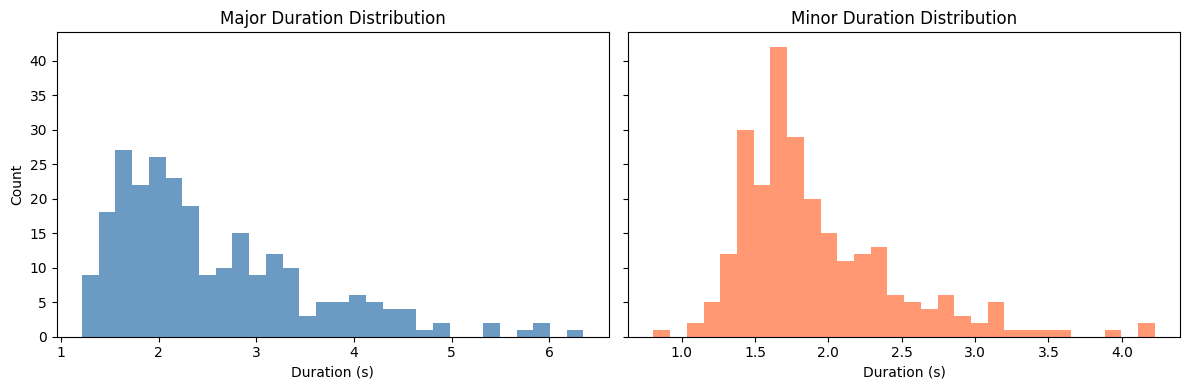

In [ ]:
def durations_for_files(files):
    durations = []
    for f in files:
        y, sr = librosa.load(str(f), sr=None)
        durations.append(librosa.get_duration(y=y, sr=sr))
    return np.array(durations)

major_durations = durations_for_files(major_files)
minor_durations = durations_for_files(minor_files)

report = pd.DataFrame({
    'maj': pd.Series(major_durations),
    'min': pd.Series(minor_durations)
})

print(report.describe().T)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
axes[0].hist(major_durations, bins=30, alpha=0.8, color='steelblue')
axes[0].set_title('Major Duration Distribution')
axes[0].set_xlabel('Duration (s)')
axes[0].set_ylabel('Count')

axes[1].hist(minor_durations, bins=30, alpha=0.8, color='coral')
axes[1].set_title('Minor Duration Distribution')
axes[1].set_xlabel('Duration (s)')

plt.tight_layout()
plt.show()

check the sample rate for every file.

In [7]:
def get_sample_rates(files):
    rates = []
    for f in files:
        rates.append(librosa.get_samplerate(str(f)))
    return np.array(rates)

major_sample_rates = get_sample_rates(major_files)
minor_sample_rates = get_sample_rates(minor_files)

# Create a DataFrame for counts
sr_counts = pd.DataFrame({
    'Major': pd.Series(major_sample_rates).value_counts(),
    'Minor': pd.Series(minor_sample_rates).value_counts()
}).fillna(0).astype(int)

print("Sample Rate Counts (Hz):")
print(sr_counts)

Sample Rate Counts (Hz):
       Major  Minor
44100    250    252
